<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/Week2_Regression/Loss_functions_CV_statsmodels.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Функции потерь в линейной регрессии и интерпретация статистических таблиц

## План

1. Какие функции потерь для линейной регрессии есть в sklearn и как они ведут себя на выбросах
2. Пайплайны с разной обработкой признаков и разными функциями потерь: сравниваем на кросс-валидации
3. Таблица коэффициентов из statsmodels (только главное) и проверка остатков с помощью Q-Q plot

Данные те же, что на прошлом занятии: цены автомобилей (Automobile Data Set).

Регуляризацию мы ещё не проходили, поэтому везде, где у модели она включена по умолчанию, выключаем её (`alpha=0`).

In [ ]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings('ignore')

In [ ]:
COLUMNS = ['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors',
           'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height',
           'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore',
           'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"

data = pd.read_csv(DATA_URL, header=None, na_values=["?"], names=COLUMNS)
data = data[data['price'].notna()].reset_index(drop=True)

y = data['price']
X = data.drop(columns='price')

num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
cat_cols = [c for c in X.columns if c not in num_cols]
X.shape, len(num_cols), len(cat_cols)

((201, 25), 15, 10)

## 1. Функции потерь в sklearn

| Функция потерь | Модель в sklearn | Что предсказывает |
|---|---|---|
| MSE | `LinearRegression()` | условное среднее |
| MAE | `QuantileRegressor(quantile=0.5, alpha=0)` | условную медиану |
| квантильная $\rho_\tau$ (pinball) | `QuantileRegressor(quantile=τ, alpha=0)` | τ-квантиль |
| Huber | `HuberRegressor(epsilon=1.35, alpha=0)` | компромисс между средним и медианой |
| MSE для $\ln(y+1)$ | `TransformedTargetRegressor(LinearRegression(), func=np.log1p, inverse_func=np.expm1)` | ≈ минимизация MSLE |

Обратите внимание на `alpha=0`: у `QuantileRegressor` по умолчанию `alpha=1.0`, у `HuberRegressor` — `alpha=0.0001`. Это коэффициенты регуляризации, и без явного `alpha=0` мы бы обучали уже не «чистую» модель.

Те же модели есть и в statsmodels: `sm.QuantReg` — квантильная регрессия, `sm.RLM(..., M=sm.robust.norms.HuberT())` — регрессия с функцией потерь Huber.

### Как функции потерь переносят выбросы

Сгенерируем линейную зависимость с шумом и добавим в правый верхний угол выбросы.

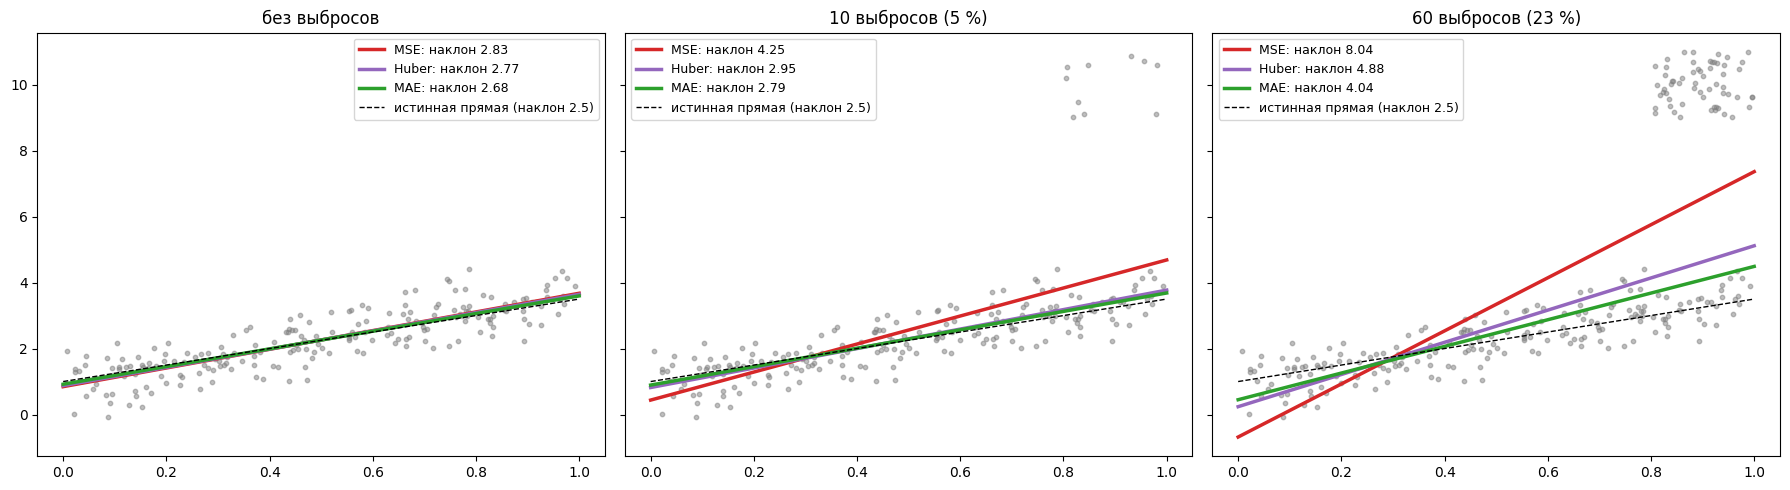

In [ ]:
from sklearn.linear_model import LinearRegression, HuberRegressor, QuantileRegressor

rng = np.random.default_rng(42)
x = rng.uniform(0, 1, 200)
y_lin = 2.5 * x + 1.0 + rng.normal(0, 0.5, 200)   # истинная прямая: y = 2.5x + 1


def add_outliers(x, y, k):
    """Добавляет k выбросов: x из [0.8, 1], y около 10"""
    xo = rng.uniform(0.8, 1.0, k)
    yo = rng.uniform(9, 11, k)
    return np.r_[x, xo], np.r_[y, yo]


losses = {
    'MSE': (LinearRegression(), 'tab:red'),
    'Huber': (HuberRegressor(epsilon=1.35, alpha=0), 'tab:purple'),
    'MAE': (QuantileRegressor(quantile=0.5, alpha=0, solver='highs'), 'tab:green'),
}

datasets = [('без выбросов', x, y_lin),
            ('10 выбросов (5 %)', *add_outliers(x, y_lin, 10)),
            ('60 выбросов (23 %)', *add_outliers(x, y_lin, 60))]

grid = np.linspace(0, 1, 50)[:, None]
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (title, xs, ys) in zip(axes, datasets):
    ax.scatter(xs, ys, s=10, alpha=0.5, color='gray')
    for name, (model, color) in losses.items():
        model.fit(xs[:, None], ys)
        ax.plot(grid, model.predict(grid), color=color, lw=2.5,
                label=f'{name}: наклон {model.coef_[0]:.2f}')
    ax.plot(grid, 2.5 * grid + 1, 'k--', lw=1, label='истинная прямая (наклон 2.5)')
    ax.set_title(title)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

* Без выбросов все три прямые почти совпадают с истинной.
* Даже 5 % выбросов сильно разворачивают прямую MSE: квадрат делает большие ошибки очень «тяжёлыми». Huber и MAE почти не реагируют.
* Когда выбросов становится много (почти четверть выборки), сдвигаются и Huber, и MAE: устойчивость не бесконечна. MAE держится дольше всех.

### Квантильная регрессия: не одна прямая, а коридор

Квантильная функция потерь с разными τ даёт разные квантили ответа. Две модели с τ = 0.1 и τ = 0.9 задают коридор, в который попадает примерно 80 % объектов.

τ = 0.1: ниже прямой 10% точек
τ = 0.5: ниже прямой 50% точек
τ = 0.9: ниже прямой 90% точек


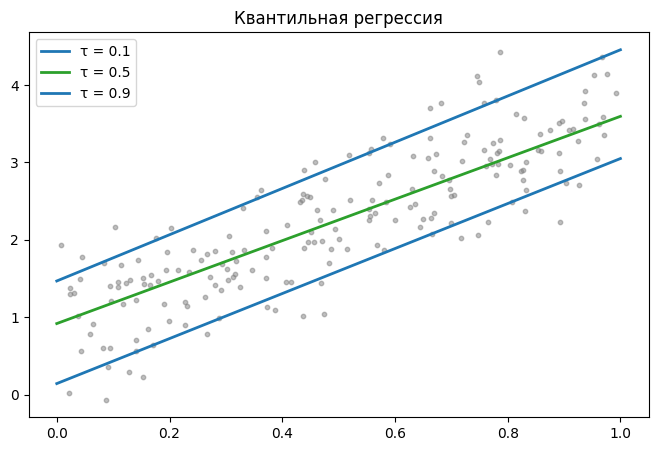

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(x, y_lin, s=10, alpha=0.5, color='gray')
for q, color in [(0.1, 'tab:blue'), (0.5, 'tab:green'), (0.9, 'tab:blue')]:
    qr = QuantileRegressor(quantile=q, alpha=0, solver='highs').fit(x[:, None], y_lin)
    plt.plot(grid, qr.predict(grid), color=color, lw=2, label=f'τ = {q}')
    share_below = (y_lin <= qr.predict(x[:, None])).mean()
    print(f'τ = {q}: ниже прямой {share_below:.0%} точек')
plt.legend()
plt.title('Квантильная регрессия')
plt.show()

## 2. Пайплайны с разной обработкой признаков и функциями потерь

Соберём пайплайны из двух «кубиков»:

* **обработка признаков** — три варианта:
  * `base` — пропуски, масштабирование, OHE (как на прошлом занятии);
  * `poly` — плюс полиномиальные признаки для `engine-size` и `horsepower`;
  * `poly+bins` — плюс бинаризация `city-mpg` по квартилям;
* **функция потерь** — MSE, Huber, MAE и MSE для $\ln(y+1)$.

Всего 3 × 4 = 12 пайплайнов. Сравним их на **кросс-валидации**: делим данные на 5 частей, по очереди учимся на четырёх и проверяем на пятой. Одно разбиение train/test на 200 объектах слишком «шумное», а среднее по пяти фолдам надёжнее. И именно пайплайн позволяет делать это честно: на каждом фолде предобработка заново подбирается только по обучающей части.

In [ ]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, PolynomialFeatures, StandardScaler


def make_preprocessor(feature_set='base'):
    """feature_set: 'base', 'poly' или 'poly+bins'"""
    poly_cols = ['engine-size', 'horsepower'] if feature_set != 'base' else []
    transformers = [
        ('num', Pipeline([('imputer', SimpleImputer(strategy='mean')),
                          ('scaler', StandardScaler())]),
         [c for c in num_cols if c not in poly_cols]),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='NA')),
                          ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]),
         cat_cols),
    ]
    if poly_cols:
        transformers.append(
            ('poly', Pipeline([('imputer', SimpleImputer(strategy='mean')),
                               ('poly', PolynomialFeatures(degree=2, include_bias=False)),
                               ('scaler', StandardScaler())]),
             poly_cols))
    if feature_set == 'poly+bins':
        transformers.append(
            ('bins', Pipeline([('imputer', SimpleImputer(strategy='mean')),
                               ('bins', KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')),
                               ('onehot', OneHotEncoder(drop='first'))]),
             ['city-mpg']))
    return ColumnTransformer(transformers)


def make_models():
    return {
        'MSE': LinearRegression(),
        'Huber': HuberRegressor(epsilon=1.35, alpha=0, max_iter=5000),
        'MAE': QuantileRegressor(quantile=0.5, alpha=0, solver='highs'),
        'MSE для ln(y+1)': TransformedTargetRegressor(regressor=LinearRegression(),
                                                       func=np.log1p, inverse_func=np.expm1),
    }

In [ ]:
from tqdm import tqdm

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
    'MAPE': 'neg_mean_absolute_percentage_error',
}

rows, fold_mae = [], {}
for feature_set in tqdm(['base', 'poly', 'poly+bins']):
    for loss_name, model in make_models().items():
        pipe = Pipeline([('preprocessor', make_preprocessor(feature_set)), ('model', model)])
        res = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
        name = f'{feature_set} | {loss_name}'
        fold_mae[name] = -res['test_MAE']
        rows.append({
            'признаки': feature_set,
            'функция потерь': loss_name,
            'MAE': -res['test_MAE'].mean(),
            'MAE std': res['test_MAE'].std(),
            'RMSE': -res['test_RMSE'].mean(),
            'R2': res['test_R2'].mean(),
            'MAPE': -res['test_MAPE'].mean(),
        })

cv_results = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
cv_results.round(3)

100%|██████████| 3/3 [00:32<00:00, 10.73s/it]


,признаки,функция потерь,MAE,MAE std,RMSE,R2,MAPE
0,base,MSE для ln(y+1),1561.585,166.670,2416.215,0.879,0.115
1,poly+bins,MSE,1708.265,231.710,2435.540,0.872,0.134
2,poly,MSE,1748.789,170.720,2498.193,0.866,0.138
3,base,Huber,1928.292,218.903,2836.309,0.841,0.150
4,poly,Huber,1941.359,481.338,3057.283,0.827,0.142
5,poly+bins,Huber,1957.273,438.762,3031.366,0.827,0.144
6,poly,MAE,1983.790,392.996,3155.820,0.796,0.141
7,base,MSE,1988.022,125.222,2751.679,0.839,0.162
8,base,MAE,2094.129,206.272,3095.511,0.795,0.161
9,poly+bins,MAE,2140.063,498.082,3570.417,0.743,0.150


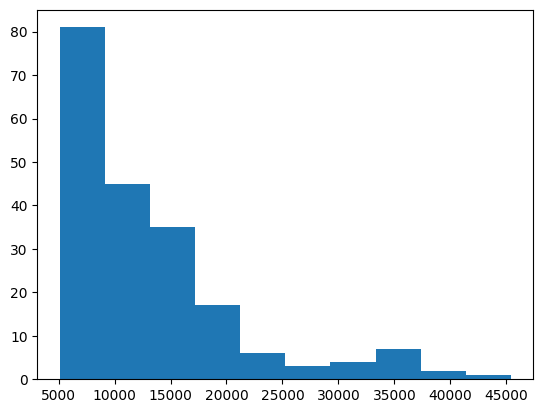

In [ ]:
plt.hist(y);

(array([15., 41., 35., 28., 21., 34.,  8.,  5.,  9.,  5.]),
 array([ 8.54071439,  8.75897189,  8.97722939,  9.19548689,  9.4137444 ,
         9.6320019 ,  9.8502594 , 10.0685169 , 10.28677441, 10.50503191,
        10.72328941]),
 <BarContainer object of 10 artists>)

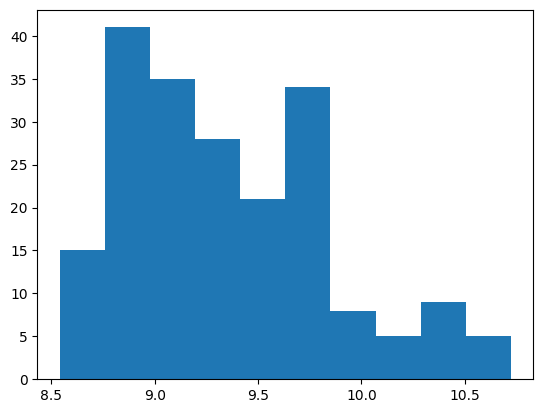

In [ ]:
plt.hist(np.log1p(y))

`neg_` в названиях scoring — потому что в sklearn «больше — лучше», и ошибки возвращаются со знаком минус. Мы сразу переворачиваем знак обратно.

Посмотрим не только на средние, но и на разброс по фолдам:

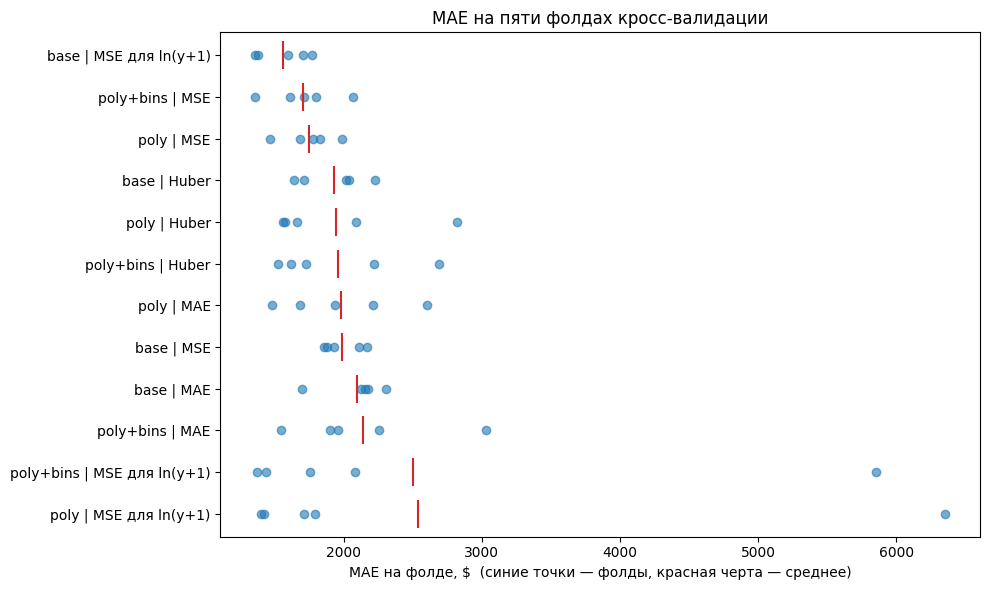

In [ ]:
order = cv_results.apply(lambda r: f"{r['признаки']} | {r['функция потерь']}", axis=1)
plt.figure(figsize=(10, 6))
for i, name in enumerate(order):
    plt.scatter(fold_mae[name], [i] * len(fold_mae[name]), color='tab:blue', alpha=0.6)
    plt.scatter(fold_mae[name].mean(), i, color='tab:red', marker='|', s=400)
plt.yticks(range(len(order)), order)
plt.gca().invert_yaxis()
plt.xlabel('MAE на фолде, $  (синие точки — фолды, красная черта — среднее)')
plt.title('MAE на пяти фолдах кросс-валидации')
plt.tight_layout()
plt.show()

Что обычно видно на этих данных:

* **MSE для ln(y+1) на базовых признаках** — одна из лучших моделей. Цены машин скошены вправо, а ошибка дорогих машин в долларах больше; логарифм выравнивает разброс (вспомните предположение об одинаковой дисперсии шума из лекции).
* **ln(y+1) вместе с полиномиальными признаками** может «взорваться» на одном из фолдов: прогноз возвращается через экспоненту, и небольшая ошибка экстраполяции превращается в огромную ошибку в долларах. Это хорошо видно по разбросу точек на графике.
* **Huber и MAE** здесь не выигрывают: грубых выбросов в данных немного, а признаков почти столько же, сколько объектов в фолде. Робастная функция потерь помогает, когда в данных есть выбросы, а не всегда.
* Разница между соседними строками часто меньше разброса по фолдам (`MAE std`). Делать выводы «модель А лучше модели Б» по разнице в пару десятков долларов нельзя.
* В теории каждая модель сильнее в «своей» метрике: MSE — по RMSE, MAE — по MAE. Но здесь MAE-модели проигрывают даже по MAE: при 60+ признаках на ~160 объектах переобучение важнее выбора функции потерь.

### Финальная проверка на отложенной выборке

Кросс-валидацией мы **выбирали** модель. Чтобы честно оценить выбранную, нужна выборка, которая в выборе не участвовала.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=123)

best = cv_results.iloc[0]
print('Лучший пайплайн на CV:', best['признаки'], '|', best['функция потерь'])

best_pipe = Pipeline([('preprocessor', make_preprocessor(best['признаки'])),
                      ('model', make_models()[best['функция потерь']])])
best_pipe.fit(X_train, y_train)
pred = best_pipe.predict(X_test)

pd.Series({
    'MAE': mean_absolute_error(y_test, pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
    'R2': r2_score(y_test, pred),
    'MAPE': mean_absolute_percentage_error(y_test, pred),
}).round(3)

Лучший пайплайн на CV: base | MSE для ln(y+1)


,0
MAE,1227.908
RMSE,1958.826
R2,0.891
MAPE,0.109


Строго говоря, отложенную выборку нужно отделять **до** кросс-валидации и не трогать, пока модель не выбрана. Здесь мы для простоты выбирали модель по CV на всех данных, поэтому оценка на тесте получается слегка оптимистичной.

## 3. Таблица коэффициентов и проверка остатков

sklearn выдаёт веса модели и метрики. Библиотека **statsmodels** выдаёт подробную таблицу: в ней много статистики, но нам сейчас нужно лишь несколько строк. Остатки модели проверим с помощью **scipy.stats**.

Возьмём небольшой набор понятных признаков и **не будем их масштабировать**: тогда вес — это изменение цены в долларах при росте признака на одну единицу.

In [ ]:
import statsmodels.api as sm

features = ['engine-size', 'horsepower', 'curb-weight', 'width', 'city-mpg']
train_means = X_train[features].mean()   # пропуски заполняем средними по train


def design_matrix(df):
    out = df[features].fillna(train_means)
    out['diesel'] = (df['fuel-type'] == 'diesel').astype(float)
    out['turbo'] = (df['aspiration'] == 'turbo').astype(float)
    out['rwd'] = (df['drive-wheels'] == 'rwd').astype(float)
    return sm.add_constant(out)   # столбец из единиц для свободного члена


A_train = design_matrix(X_train)
ols = sm.OLS(y_train, A_train).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.841
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     93.23
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.90e-52
Time:                        10:22:45   Log-Likelihood:                -1429.1
No. Observations:                 150   AIC:                             2876.
Df Residuals:                     141   BIC:                             2903.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const       -5.071e+04   1.61e+04     -3.155      

### Что смотреть в таблице

Таблица большая, но для нас важны четыре вещи:

* **`R-squared`, `Adj. R-squared`** — знакомые по лекции $R^2$ и скорректированный $R^2$ (здесь — на обучающей выборке).
* **`coef`** — веса модели. Например, вес `horsepower` около 73: каждая лишняя лошадиная сила при прочих равных добавляет к прогнозу цены около 73 долларов.
* **`[0.025  0.975]`** — диапазон, в котором, скорее всего, лежит «настоящий» вес. Выборка у нас небольшая, поэтому вес оценён неточно, и statsmodels показывает эту неточность. Если диапазон **захватывает ноль**, мы не можем уверенно сказать, что признак вообще влияет на цену.
* **`P>|t|`** — то же самое одним числом: маленькое значение (меньше 0.05) — вес надёжно отличается от нуля, большое — нет.

Ещё одна строка напрямую связана с лекцией: **`Log-Likelihood`** — это логарифм правдоподобия, который максимизирует ММП. Остальное (F-тест, AIC, Omnibus и т. д.) пока можно не смотреть.

### Что говорят коэффициенты

* У `engine-size`, `horsepower`, `width`, `rwd`, `diesel` диапазоны не захватывают ноль — эти признаки надёжно влияют на прогноз.
* У `curb-weight` и `city-mpg` диапазоны захватывают ноль. Но это **не значит**, что масса машины не влияет на цену! Эти признаки сильно связаны с другими (тяжёлые машины мощнее и больше расходуют), и модели трудно разделить их вклад:

In [ ]:
A_train[features].corr().round(2)

,engine-size,horsepower,curb-weight,width,city-mpg
engine-size,1.00,0.83,0.85,0.71,-0.68
horsepower,0.83,1.00,0.74,0.58,-0.83
curb-weight,0.85,0.74,1.00,0.85,-0.75
width,0.71,0.58,0.85,1.00,-0.62
city-mpg,-0.68,-0.83,-0.75,-0.62,1.00


### Проверяем предположения о шуме: Q-Q plot

На лекции мы выяснили: MSE — это ММП, если шум **нормальный** и с **одинаковым разбросом**. Шум мы не видим, но видим остатки $e_i = y_i - a(x_i)$ — по ним и проверим.

**Q-Q plot** (quantile–quantile plot) сравнивает, как на самом деле распределены наши остатки и как они были бы распределены, будь они нормальными.

**Как он строится:**

1. Сортируем остатки по возрастанию: $e_{(1)} \le e_{(2)} \le \dots \le e_{(l)}$.
2. Для каждого места $i$ считаем, какое значение стояло бы на этом месте у нормального распределения, — квантиль уровня $\frac{i - 0.5}{l}$. При $l = 150$ самый маленький остаток сравниваем с квантилем уровня 0.3 % (это примерно $-2.7$ стандартных отклонения), средний по счёту — с нулём, самый большой — с квантилем уровня 99.7 % (примерно $+2.7$).
3. Ставим точки: по горизонтали — теоретический квантиль, по вертикали — наш отсортированный остаток.

**Как читать:**

* Остатки нормальные — точки лежат **на прямой**. Наклон прямой — разброс остатков, сдвиг — их среднее.
* Левый конец уходит **вниз**, правый — **вверх**: хвосты **тяжелее** нормальных. Большие ошибки встречаются чаще, чем допускает нормальное распределение, — именно в такой ситуации MSE страдает от выбросов.
* Наоборот, левый конец загибается вверх, а правый — вниз: хвосты легче нормальных, больших ошибок почти нет.
* Точки идут дугой — распределение остатков несимметрично.

Почему не гистограмма? На гистограмме хвосты — это пара столбиков высотой 1–2, их почти не видно. Q-Q plot как раз «растягивает» хвосты.

Построим Q-Q plot руками, а рядом нарисуем остатки против прогноза — так проверим, одинаков ли разброс.

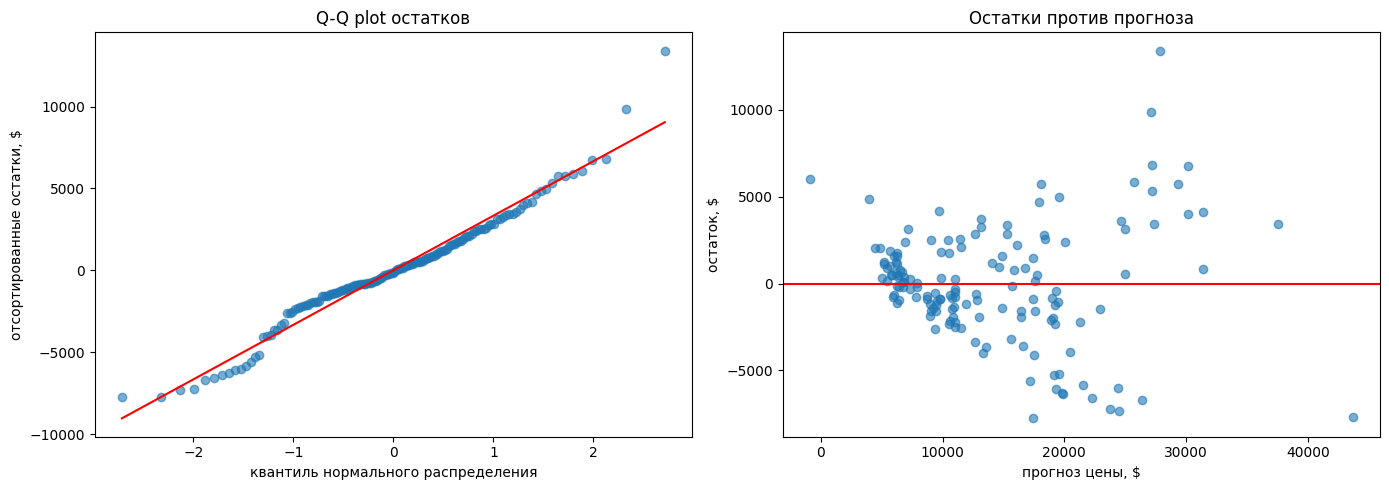

In [ ]:
resid = ols.resid
l = len(resid)

sorted_resid = np.sort(resid)                       # шаг 1: сортируем остатки
levels = (np.arange(1, l + 1) - 0.5) / l            # шаг 2: уровни (i - 0.5) / l
theoretical = stats.norm.ppf(levels)                # ... и квантили нормального распределения

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(theoretical, sorted_resid, alpha=0.6)   # шаг 3: точки
# прямая, на которой лежали бы точки у нормальных остатков: среднее + σ · квантиль
axes[0].plot(theoretical, resid.mean() + resid.std() * theoretical, color='red')
axes[0].set_xlabel('квантиль нормального распределения')
axes[0].set_ylabel('отсортированные остатки, $')
axes[0].set_title('Q-Q plot остатков')

axes[1].scatter(ols.fittedvalues, resid, alpha=0.6)
axes[1].axhline(0, color='red')
axes[1].set_xlabel('прогноз цены, $')
axes[1].set_ylabel('остаток, $')
axes[1].set_title('Остатки против прогноза')

plt.tight_layout()
plt.show()

* На Q-Q plot правый конец заметно уходит вверх: самые большие остатки (модель сильно недооценила цену) больше, чем допускает нормальное распределение, — **тяжёлый правый хвост**. Левый конец почти на прямой: остатки **несимметричны**, крупно ошибаемся в основном в одну сторону.
* Справа видно, что разброс остатков растёт вместе с ценой — он **не одинаковый**.

Оба предположения MSE нарушены. Лекарство из лекции — логарифмировать целевую переменную. В scipy Q-Q plot строится одной строкой: `stats.probplot(resid, dist='norm', plot=ax)`.

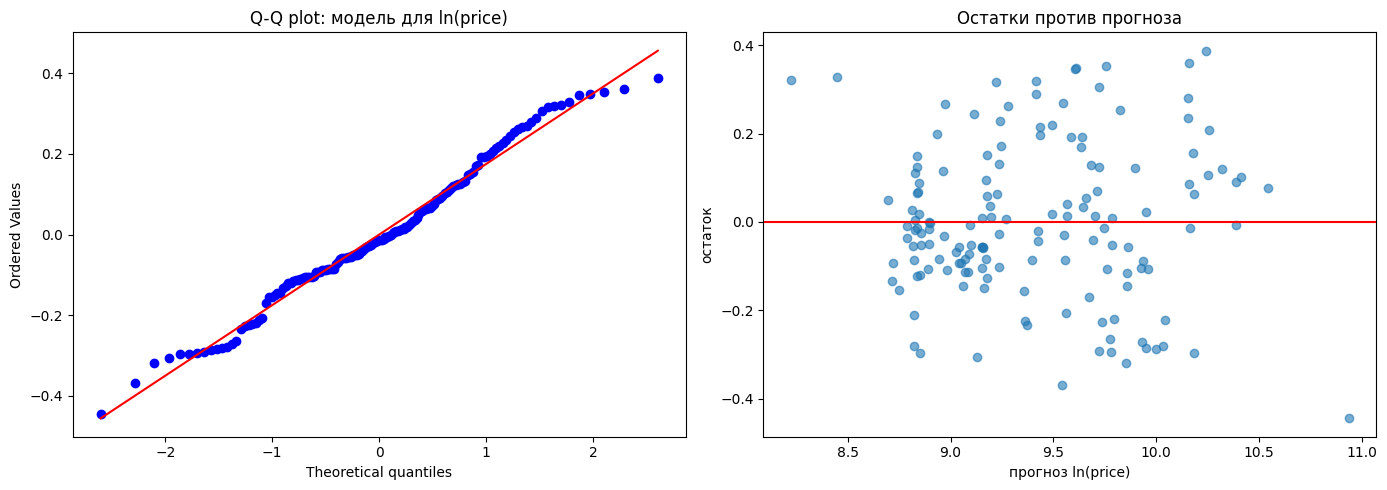

R² модели для ln(price): 0.891


In [ ]:
ols_log = sm.OLS(np.log(y_train), A_train).fit()
resid_log = ols_log.resid

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
stats.probplot(resid_log, dist='norm', plot=axes[0])
axes[0].set_title('Q-Q plot: модель для ln(price)')
axes[1].scatter(ols_log.fittedvalues, resid_log, alpha=0.6)
axes[1].axhline(0, color='red')
axes[1].set_xlabel('прогноз ln(price)')
axes[1].set_ylabel('остаток')
axes[1].set_title('Остатки против прогноза')
plt.tight_layout()
plt.show()

print(f'R² модели для ln(price): {ols_log.rsquared:.3f}')

* Точки на Q-Q plot легли на прямую, разброс остатков стал ровным: для $\ln(\text{price})$ предположения MSE выполняются гораздо лучше. Это объясняет, почему на кросс-валидации модель с логарифмом оказалась одной из лучших.
* Смысл весов изменился: вес $w$ теперь означает, что при росте признака на 1 цена меняется примерно на $100 \cdot w$ %. Например, вес `horsepower` около 0.005 — каждая лошадиная сила добавляет к цене около 0.5 %.

## Итоги

* В sklearn есть линейные модели с разными функциями потерь: MSE, MAE и квантильная, Huber, MSE для $\ln(y+1)$. Регуляризацию по умолчанию выключаем через `alpha=0`.
* Робастные функции потерь спасают от выбросов, но не бесконечно, и помогают не на всех данных.
* Пайплайны удобно сравнивать на кросс-валидации: смотрим и на среднее, и на разброс по фолдам.
* В таблице statsmodels главное — веса и их диапазоны: если диапазон захватывает ноль, влияние признака не доказано.
* Q-Q plot и график «остатки против прогноза» показывают, выполняются ли предположения MSE. Если нет — пробуем логарифм целевой переменной или другую функцию потерь.